## Select the best model based on precision, recall, and F1-score, applying custom weighting strategies for imbalanced datasets and justifying selection using a detailed performance analysis.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv('heart.csv')                          
rng = np.random.default_rng(0)
pos, neg = np.where(df['target'] == 1)[0], np.where(df['target'] == 0)[0]
keep = np.concatenate([neg, rng.choice(pos, 35, replace=False)])
X, y = df.drop(columns='target').values[keep].astype(float), df['target'].values[keep]
print(X.shape, '| positives:', y.sum(), '| positive share:', y.mean().round(3))

(173, 13) | positives: 35 | positive share: 0.202


In [2]:
def prf(t, pred, beta=1):
    tp, fp, fn = np.sum(pred & (t == 1)), np.sum(pred & (t == 0)), np.sum(~pred & (t == 1))
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    f = lambda b: (1 + b**2) * prec * rec / max(b**2 * prec + rec, 1e-9)
    return dict(prec=float(prec), rec=float(rec), f1=float(f(1)), f2=float(f(2)), acc=float(np.mean(pred == t)))

# Baseline: sabko negative bol do
print('All-negative baseline:', {k: round(v, 3) for k, v in prf(y, np.zeros(len(y), bool)).items()})

All-negative baseline: {'prec': 0.0, 'rec': 0.0, 'f1': 0.0, 'f2': 0.0, 'acc': 0.798}


In [3]:
def sample_weights(t, strategy):
    r = np.sum(t == 0) / np.sum(t == 1)                          
    wpos = {'none': 1.0, 'sqrt': np.sqrt(r), 'balanced': r}[strategy]
    return np.where(t == 1, wpos, 1.0)

models = {
    'LR':   lambda: LogisticRegression(max_iter=1000),
    'NB':   lambda: GaussianNB(),
    'Tree': lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=0),
    'SVM':  lambda: SVC(probability=True, random_state=0),
    'RF':   lambda: RandomForestClassifier(100, min_samples_leaf=3, random_state=0),
}
strategies = ['none', 'sqrt', 'balanced']

def fit_prob(name, A, t, strategy, B):
    return models[name]().fit(A, t, sample_weight=sample_weights(t, strategy)).predict_proba(B)[:, 1]

In [4]:
def strat_folds(t, k, seed):
    r = np.random.default_rng(seed); parts = [np.array_split(r.permutation(np.where(t == c)[0]), k) for c in (0, 1)]
    return [np.concatenate([parts[0][i], parts[1][i]]) for i in range(k)]

def scale(A, B): mu, sd = A.mean(0), A.std(0); return (A - mu) / sd, (B - mu) / sd

def best_threshold(name, strategy, A, t, seed):
    oof = np.zeros(len(t))
    for f in strat_folds(t, 5, seed):
        tr = np.setdiff1d(np.arange(len(t)), f); a, b = scale(A[tr], A[f])
        oof[f] = fit_prob(name, a, t[tr], strategy, b)
    grid = np.arange(0.05, 0.96, 0.05)
    return grid[np.argmax([prf(t, oof > g)['f1'] for g in grid])]

In [5]:
res, thr_used = {}, {}
for rep in range(6):
    folds = strat_folds(y, 5, rep)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        A, B = scale(X[tr], X[te]); seed = rep * 5 + k
        for n in models:
            for s in strategies:
                p = fit_prob(n, A, y[tr], s, B); g = best_threshold(n, s, X[tr], y[tr], seed)
                res.setdefault((n, s, 'thr 0.5'), []).append(prf(y[te], p > 0.5))
                res.setdefault((n, s, 'thr tuned'), []).append(prf(y[te], p > g))
                thr_used.setdefault((n, s), []).append(g)
print('Variants:', len(res), '| folds each:', len(next(iter(res.values()))))

Variants: 30 | folds each: 30


In [6]:
rows = []
for (n, s, th), ms in res.items():
    g = lambda c: np.array([m[c] for m in ms])
    rows.append((n, s, th, g('f1').mean(), g('prec').mean(), g('rec').mean(), f"{g('prec').mean():.3f}", f"{g('rec').mean():.3f}", f"{g('f1').mean():.3f} +- {g('f1').std():.3f}", f"{g('f2').mean():.3f}", f"{g('acc').mean():.3f}"))
rank = pd.DataFrame(rows, columns=['Model', 'Weighting', 'Threshold', 'f1v', 'pv', 'rv', 'Precision', 'Recall', 'F1', 'F2', 'Accuracy']).sort_values('f1v', ascending=False)
rank.drop(columns=['f1v', 'pv', 'rv']).head(10).reset_index(drop=True)

,Model,Weighting,Threshold,Precision,Recall,F1,F2,Accuracy
0,NB,none,thr 0.5,0.614,0.762,0.665 +- 0.123,0.716,0.845
1,NB,balanced,thr tuned,0.594,0.757,0.654 +- 0.131,0.708,0.833
2,LR,sqrt,thr 0.5,0.634,0.733,0.654 +- 0.116,0.694,0.846
3,NB,sqrt,thr 0.5,0.564,0.795,0.647 +- 0.118,0.725,0.824
4,LR,balanced,thr 0.5,0.579,0.795,0.645 +- 0.110,0.722,0.825
5,NB,sqrt,thr tuned,0.586,0.743,0.640 +- 0.120,0.693,0.828
6,NB,none,thr tuned,0.587,0.738,0.639 +- 0.136,0.690,0.829
7,LR,none,thr tuned,0.576,0.752,0.635 +- 0.118,0.696,0.830
8,LR,balanced,thr tuned,0.581,0.757,0.634 +- 0.110,0.698,0.828
9,SVM,none,thr tuned,0.629,0.686,0.633 +- 0.154,0.658,0.841


In [7]:
eff = rank.groupby(['Weighting', 'Threshold'])[['pv', 'rv', 'f1v']].mean().round(3); eff.columns = ['Precision', 'Recall', 'F1']
print(eff.loc[[(s, t) for s in strategies for t in ['thr 0.5', 'thr tuned']]].to_string())
print('\nAverage tuned threshold per weighting:', {s: round(float(np.mean([v for (n, ss), vs in thr_used.items() if ss == s for v in vs])), 2) for s in strategies})

                     Precision  Recall     F1
Weighting Threshold                          
none      thr 0.5        0.659   0.513  0.537
          thr tuned      0.559   0.694  0.598
sqrt      thr 0.5        0.631   0.603  0.576
          thr tuned      0.552   0.704  0.598
balanced  thr 0.5        0.592   0.669  0.590
          thr tuned      0.550   0.720  0.603

Average tuned threshold per weighting: {'none': 0.33, 'sqrt': 0.41, 'balanced': 0.51}


In [8]:
f1 = {k: np.array([m['f1'] for m in ms]) for k, ms in res.items()}
best = max(f1, key=lambda k: f1[k].mean()); n_f = len(f1[best]); ratio = 1 / 4        
short = []
for k in f1:
    d = f1[best] - f1[k]
    t_c = 0 if k == best else d.mean() / np.sqrt(d.var(ddof=1) * (1 / n_f + ratio) + 1e-12)
    if t_c < 2.045: short.append(k)                                                  
f2 = {k: np.mean([m['f2'] for m in res[k]]) for k in short}
rec = {k: np.mean([m['rec'] for m in res[k]]) for k in short}
choice = max(short, key=f2.get)
print('Top 3 by F2 in shortlist:', [(k, round(f2[k], 3)) for k in sorted(f2, key=f2.get, reverse=True)[:3]])
print('Best F1 variant:', best, round(f1[best].mean(), 3))
print('Not significantly worse (shortlist):', len(short), 'variants')
print('Chosen (highest F2 in shortlist):', choice, '| F1', round(f1[choice].mean(), 3), '| F2', round(f2[choice], 3), '| recall', round(rec[choice], 3),
      '| precision', round(np.mean([m['prec'] for m in res[choice]]), 3))

Top 3 by F2 in shortlist: [(('NB', 'balanced', 'thr 0.5'), np.float64(0.726)), (('NB', 'sqrt', 'thr 0.5'), np.float64(0.725)), (('LR', 'balanced', 'thr 0.5'), np.float64(0.722))]
Best F1 variant: ('NB', 'none', 'thr 0.5') 0.665
Not significantly worse (shortlist): 27 variants
Chosen (highest F2 in shortlist): ('NB', 'balanced', 'thr 0.5') | F1 0.624 | F2 0.726 | recall 0.824 | precision 0.513


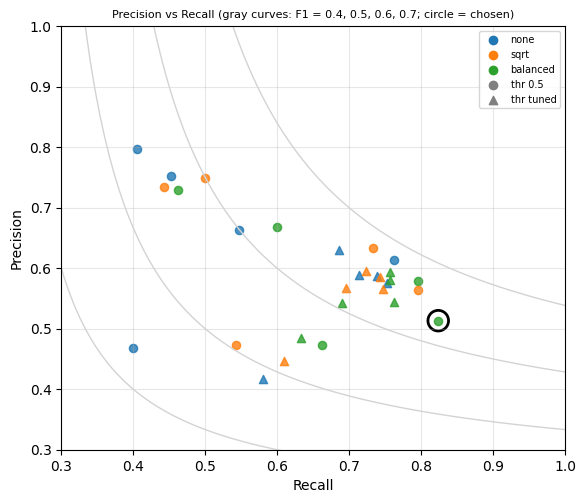

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for f in [0.4, 0.5, 0.6, 0.7]:
    r = np.linspace(f / (2 - f), 1, 100); ax.plot(r, f * r / (2 * r - f), color='lightgray', lw=1)
col = {'none': 'tab:blue', 'sqrt': 'tab:orange', 'balanced': 'tab:green'}
for (n, s, th), ms in res.items():
    ax.scatter(np.mean([m['rec'] for m in ms]), np.mean([m['prec'] for m in ms]), c=col[s], marker='o' if th == 'thr 0.5' else '^', s=35, alpha=0.8)
ax.scatter(rec[choice], np.mean([m['prec'] for m in res[choice]]), s=220, facecolors='none', edgecolors='k', linewidths=2)
for s in strategies: ax.scatter([], [], c=col[s], label=s)
ax.scatter([], [], c='gray', marker='o', label='thr 0.5'); ax.scatter([], [], c='gray', marker='^', label='thr tuned')
ax.set_xlim(0.3, 1); ax.set_ylim(0.3, 1); ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Precision vs Recall (gray curves: F1 = 0.4, 0.5, 0.6, 0.7; circle = chosen)', fontsize=8); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.show()